# Cien encuestas: ¿cuántas fallan?

**Jornada 3 · Bloque 3.2 · Muestra, variabilidad e intervalos · Demo en directo**

**Cómo usarlo.** En Google Colab: menú *Entorno de ejecución → Ejecutar todo* (en inglés, *Runtime → Run all*); la primera vez tarda unos segundos en descargar los datos del curso. En Jupyter: *Ejecutar → Ejecutar todo*. Luego mueve los controles. No hace falta tocar el código: está escondido y solo carga los datos y dibuja. Si quieres verlo, pulsa los tres puntos que aparecen en las celdas ocultas.

In [1]:
# Preparación: busca la carpeta del proyecto, carga el estilo del curso y los datos.
# No hace falta tocar nada.
import sys
from pathlib import Path


def buscar_proyecto():
    """La carpeta que contiene datos/, scripts/estilo.py y cuadernos/laboratorio.py."""
    aqui = Path.cwd()
    candidatas = [aqui, *aqui.parents,
                  Path("/content/cursos-analitica-datos"),               # Colab, subida a mano
                  Path("/content/drive/MyDrive/cursos-analitica-datos")]  # Colab, desde Drive
    for carpeta in candidatas:
        if (carpeta / "scripts" / "estilo.py").exists() and (carpeta / "cuadernos" / "laboratorio.py").exists():
            return carpeta
    if "google.colab" in sys.modules:  # en Colab, descarga una vez el material público del curso
        import subprocess
        destino = Path("/content/curso-analitica-cuadernos")
        if not destino.exists():
            subprocess.run(["git", "clone", "--quiet", "--depth", "1",
                            "https://github.com/castrorbea/curso-analitica-cuadernos.git", str(destino)], check=True)
        return destino
    raise FileNotFoundError("No encuentro el proyecto: abre este cuaderno desde la carpeta cuadernos/.")


PROYECTO = buscar_proyecto()
DATOS = PROYECTO / "datos"
for ruta in (PROYECTO / "scripts", PROYECTO / "cuadernos"):  # ../scripts y la carpeta de este cuaderno
    if str(ruta) not in sys.path:
        sys.path.insert(0, str(ruta))

import ipywidgets as widgets
from IPython.display import display

import estilo  # paleta, tipografía y formato numérico español del curso
import laboratorio as lab  # cálculos y gráficos de estos cuadernos

try:  # en Google Colab, los controles necesitan activar este gestor
    from google.colab import output
    output.enable_custom_widget_manager()
except ImportError:
    pass

ESTILO = {"description_width": "initial"}
BOTONES = {"description_width": "initial", "button_width": "auto"}

caramelos = lab.cargar_caramelos(DATOS)
fallan = (caramelos["¿Contiene el 20 %?"] == "no").sum()
print(f"Datos listos: {len(caramelos)} encuestas del curso, de las que fallan {fallan}")

Datos listos: 100 encuestas del curso, de las que fallan 5


## La pregunta

Una fábrica hace caramelos y el 20 % son azules. Nosotros no lo sabemos: sacamos una muestra, contamos y
damos un intervalo «del 95 %». ¿Qué promete exactamente ese 95 %? Menos de lo que parece, y bastante más
que un número a secas.

## El experimento

Cada línea es una encuesta: una muestra de caramelos al azar y su intervalo. Cambia el tamaño de la
muestra y el nivel de confianza, o pide otras 100 encuestas. El estado inicial es el del curso
(200 caramelos y 95 %): fallan exactamente 5, las mismas de la ficha del caso.

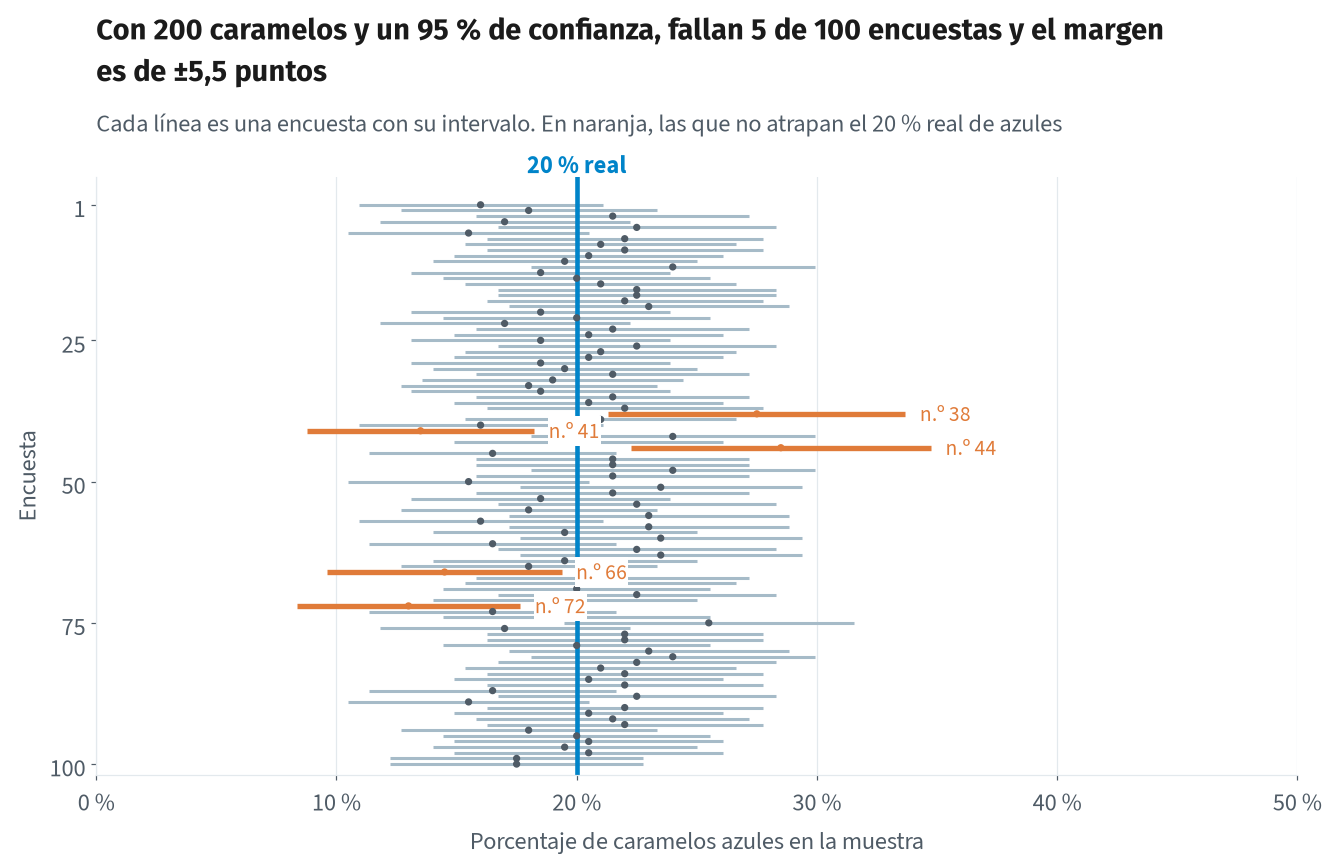

In [2]:
# El experimento: 100 encuestas sobre la misma fábrica de caramelos.
n = widgets.SelectionSlider(options=[(estilo.num(x), x) for x in lab.TAMANOS], value=200,
                            continuous_update=False, description="Caramelos por encuesta:", style=ESTILO,
                            layout=widgets.Layout(width="550px"))
nivel = widgets.ToggleButtons(options=[("80 %", 80), ("90 %", 90), ("95 %", 95), ("99 %", 99)],
                              value=95, description="Confianza:", style=BOTONES)
semilla = widgets.IntText(value=lab.SEMILLA_CARAMELOS)  # no se ve: la cambian los botones
otras = widgets.Button(description="Otras 100 encuestas", icon="refresh", button_style="info",
                      layout=widgets.Layout(width="auto"))
volver = widgets.Button(description="Volver a las del curso", icon="undo", layout=widgets.Layout(width="auto"))
otras.on_click(lambda _: setattr(semilla, "value", semilla.value + 1))
volver.on_click(lambda _: setattr(semilla, "value", lab.SEMILLA_CARAMELOS))


def dibujar(n, nivel, semilla):
    lab.mostrar(lab.dibujar_intervalos(n, nivel, semilla))


grafico = widgets.interactive_output(dibujar, {"n": n, "nivel": nivel, "semilla": semilla})
display(widgets.VBox([n, nivel, widgets.HBox([otras, volver]), grafico]))

## Qué observar

1. Con 200 caramelos y el 95 %, cuenta las que fallan. Si solo tuvieras una encuesta, ¿sabrías si es
   de las que fallan?
2. Pulsa «Otras 100 encuestas» varias veces. ¿Fallan siempre 5? ¿Alrededor de cuántas?
3. Sube el tamaño de la muestra: ¿qué cambia, el número de fallos o el ancho de los intervalos?
   ¿Y si subes la confianza al 99 %?
4. ¿Por qué no pedimos siempre el 99 %? (Pista: el repartidor que dice «llego entre las 8 y las 20»
   nunca falla, y nunca sirve.)

## Mensaje clave

> **Una muestra bien elegida vale más que una enorme mal elegida.**

Todas las muestras de este cuaderno son al azar. Si la muestra está sesgada, el intervalo no lo arregla.
Y el mensaje de la jornada: *un número sin su incertidumbre es una opinión con decimales.*

## Para curiosos

Con muestras muy pequeñas, la fórmula sencilla del intervalo se queda corta (si no sale ningún azul, el
intervalo mide cero). En el avanzado se ven fórmulas mejores y qué pasa cuando los datos no son
independientes entre sí: los intervalos de manual salen demasiado estrechos.